In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

I0000 00:00:1794247829.299868   38649 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794247829.329355   38649 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
np.random.seed(42)
import tensorflow as tf
tf.random.set_seed(42)

[*********************100%***********************]  1 of 1 completed


,Close
Date,
2018-01-02,40.232384
2018-01-03,40.225361
2018-01-04,40.412224
2018-01-05,40.872326
2018-01-08,40.720516


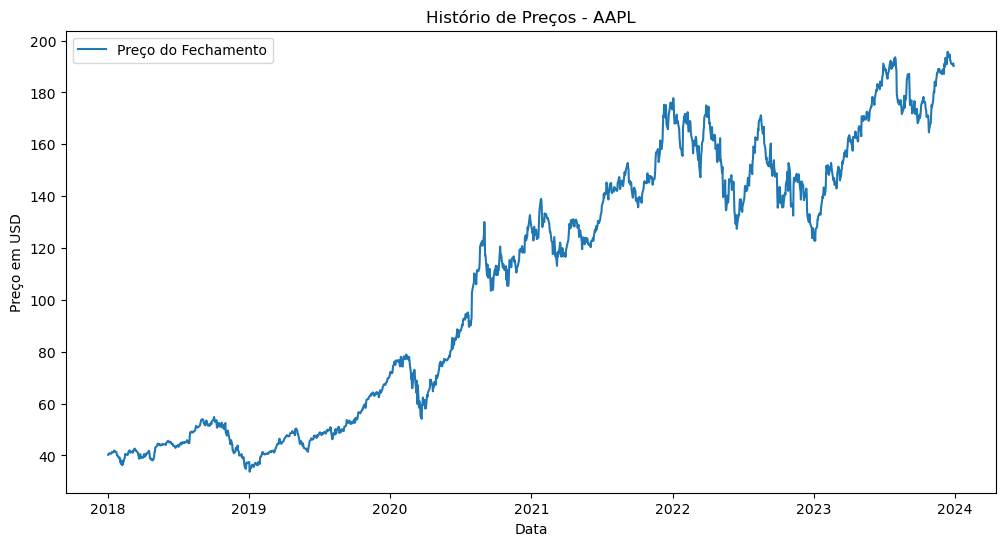

In [5]:
import requests

# Cria uma sessão simulando um navegador comum (Chrome no Windows)
session = requests.Session()
session.headers.update(
    {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'}
)

ticker = 'AAPL'
# Adiciona a sessão ao método download
df = yf.download(ticker, start='2018-01-01', end='2023-12-31', auto_adjust=True, session=session)

if 'Adj Close' in df.columns:
    data = df[['Adj Close']]
elif ('Adj Close', ticker) in df.columns:
    data = df[[('Adj Close', ticker)]]
else:
    data = df[['Close']]

data.columns = ['Close']
display(data.head())

plt.figure(figsize=(12, 6))
plt.plot(data, label='Preço do Fechamento')
plt.title('Histório de Preços - AAPL')
plt.xlabel('Data')
plt.ylabel('Preço em USD')
plt.legend()
plt.show()

In [6]:
dataset = data.values
training_data_len = int(np.ceil(len(dataset)*0.8))

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(dataset)

train_data = scaled_data[0:int(training_data_len), :]

X_train = []
y_train = []

for i in range(60, len(train_data)):
    X_train.append(train_data[i-60: i, 0])
    y_train.append(train_data[i, 0])

X_train, y_train = np.array(X_train), np.array(y_train)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))

In [8]:
model = Sequential()
model.add(LSTM(units=50,return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))
model.add(LSTM(units=50,return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(units=1))

model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, batch_size=32, epochs=15, validation_split=0.1)

Epoch 1/15


/home/anderson/miniconda3/envs/intelligent_systems/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
I0000 00:00:1794248128.345707   39744 cuda_dnn.cc:461] Loaded cuDNN version 91700


33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0283 - val_loss: 0.0030
Epoch 2/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0035 - val_loss: 0.0022
Epoch 3/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0026 - val_loss: 0.0028
Epoch 4/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0027 - val_loss: 0.0021
Epoch 5/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0024 - val_loss: 0.0020
Epoch 6/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0026 - val_loss: 0.0037
Epoch 7/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0022 - val_loss: 0.0019
Epoch 8/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0023 - val_loss: 0.0034
Epoch 9/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0021 - val_loss: 0.0018
Epoch 10/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0020 - val_loss: 0.0034
Epoch 11/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0021 - val_loss: 0.0017
Epoch 12/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0018 - val_l

In [9]:
test_data = scaled_data[training_data_len - 60: , :]
X_test = []
y_test = dataset[training_data_len: , :]

for i in range(60, len(test_data)):
    X_test.append(test_data[i-60: i, 0])

X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


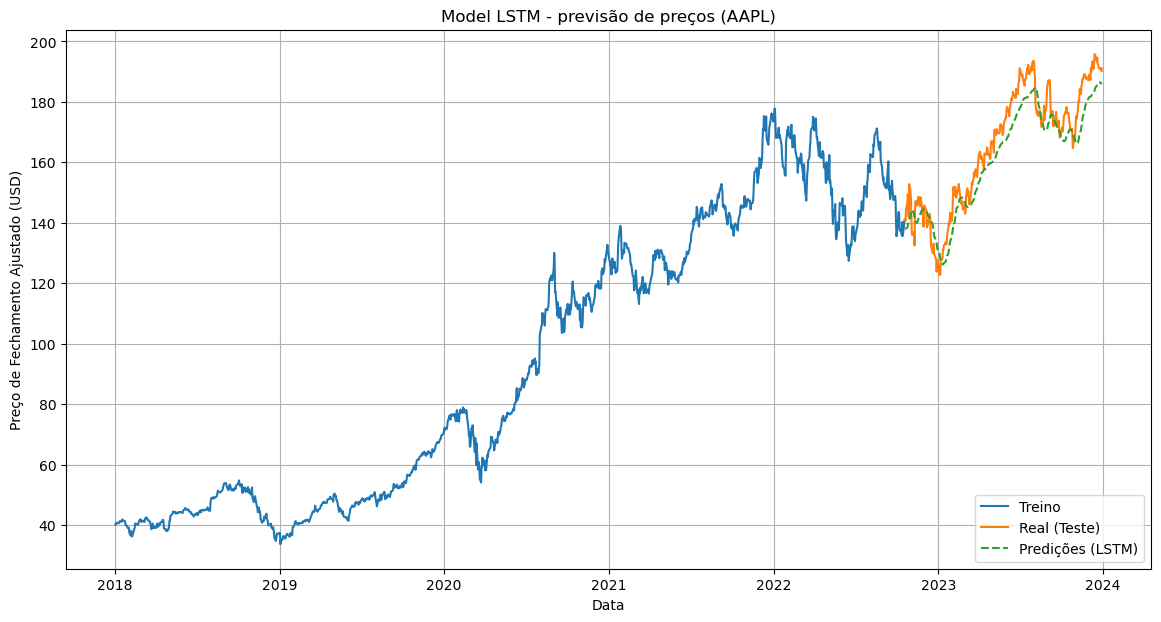

In [14]:
train = data[:training_data_len]
valid = data[training_data_len:].copy()
valid['Predictions'] = predictions

plt.figure(figsize=(14, 7))
plt.title('Model LSTM - previsão de preços (AAPL)')
plt.xlabel('Data')
plt.ylabel('Preço de Fechamento Ajustado (USD)')

plt.plot(train['Close'], label='Treino')
plt.plot(valid['Close'], label='Real (Teste)')
plt.plot(valid['Predictions'], label='Predições (LSTM)', linestyle='--')
plt.legend(loc ='lower right')
plt.grid(True)
plt.show()